# RAG-Powered Search Engine — Q&A over arXiv Research Papers

**Capstone Project — Option 2: RAG-Powered Search Engine**

## 1. Problem Statement

Researchers and engineers waste significant time manually searching and reading through
research paper abstracts to find relevant prior work. A keyword search (e.g. Ctrl+F or
basic search) fails when the right answer is phrased differently from the query, and
reading dozens of abstracts to answer a single question doesn't scale.

**Goal:** Build a Retrieval-Augmented Generation (RAG) system that:
1. Ingests research paper metadata + abstracts from a live public API (arXiv).
2. Indexes them for fast semantic (meaning-based, not keyword) search.
3. Given a natural-language question, retrieves the most relevant paper chunks.
4. Synthesizes a grounded, cited answer using an LLM — falling back gracefully to
   extractive results if no LLM key is configured.

This mirrors a real data-engineering RAG use case: ingest → transform/chunk → embed →
index → serve, and is designed so each local component (FAISS, sentence-transformers)
has a documented 1:1 swap-in for its GCP-managed equivalent (Vertex AI Vector Search,
Vertex AI Embeddings, Gemini via Vertex AI).

## 2. Setup

In [1]:
import sys, os, json
sys.path.append("..")  # repo root, if running notebook from a notebooks/ subfolder — harmless if not

from ingest import run as ingest_run
from rag.pipeline import RAGPipeline
from rag.chunking import chunk_text

DATA_DIR = "data"
CORPUS_PATH = f"{DATA_DIR}/corpus.jsonl"
INDEX_DIR = f"{DATA_DIR}/index"

os.makedirs(DATA_DIR, exist_ok=True)
print("Environment ready.")

2026-09-05 20:21:56,538 | INFO | Loading faiss.
2026-09-05 20:21:56,567 | INFO | Successfully loaded faiss.


Environment ready.


## 3. Data Ingestion

Pulls research paper metadata (title, abstract, authors, categories) from the public
**arXiv API** — no API key required. This step is written the way a GCP Cloud Function
would be structured (fetch → validate → normalize → persist), so it can be lifted
almost unchanged into a Cloud Function that lands data in GCS/BigQuery instead of a
local JSONL file.

In [2]:
records = ingest_run(
    query="retrieval augmented generation",
    max_results=60,
    out_path=CORPUS_PATH,
)
print(f"Ingested {len(records)} papers")
records[0]

2026-09-05 20:21:56,596 | INFO | Fetching arXiv batch start=0 n=25
2026-09-05 20:22:00,255 | INFO | Fetching arXiv batch start=25 n=25
2026-09-05 20:22:19,614 | INFO | Fetching arXiv batch start=50 n=10
2026-09-05 20:22:23,170 | INFO | Wrote 60 records to data/corpus.jsonl


Ingested 60 papers


{'id': 'http://arxiv.org/abs/2411.18583v1',
 'title': 'Automated Literature Review Using NLP Techniques and LLM-Based Retrieval-Augmented Generation',
 'abstract': 'This research presents and compares multiple approaches to automate the generation of literature reviews using several Natural Language Processing (NLP) techniques and retrieval-augmented generation (RAG) with a Large Language Model (LLM). The ever-increasing number of research articles provides a huge challenge for manual literature review. It has resulted in an increased demand for automation. Developing a system capable of automatically generating the literature reviews from only the PDF files as input is the primary objective of this research work. The effectiveness of several Natural Language Processing (NLP) strategies, such as the frequency-based method (spaCy), the transformer model (Simple T5), and retrieval-augmented generation (RAG) with Large Language Model (GPT-3.5-turbo), is evaluated to meet the primary objec

## 4. Chunking

Abstracts are short, but we still chunk with overlap so the pipeline generalizes to longer documents (e.g. full papers) without code changes.

In [3]:
sample_chunks = chunk_text(records[0]["abstract"], chunk_size=220, overlap=40)
print(f"Sample abstract produced {len(sample_chunks)} chunk(s)")
sample_chunks[0][:300]

Sample abstract produced 1 chunk(s)


'This research presents and compares multiple approaches to automate the generation of literature reviews using several Natural Language Processing (NLP) techniques and retrieval-augmented generation (RAG) with a Large Language Model (LLM). The ever-increasing number of research articles provides a h'

## 5. Embedding + Indexing

Embeddings are generated locally with `sentence-transformers/all-MiniLM-L6-v2` (free,
no API key) and stored in a FAISS flat index using cosine similarity.

> **GCP production note:** swap `Embedder` for a call to Vertex AI's
> `text-embedding-004` model, and swap `VectorStore` for Vertex AI Vector Search
> (a managed ANN index). The `.encode()` / `.add()` / `.search()` interfaces are
> designed to stay identical either way.

In [4]:
from rag.embeddings import Embedder

# Auto-selects MPS on Apple Silicon, CUDA on NVIDIA, else CPU.
pipeline = RAGPipeline(embedder=Embedder())
print(f"Embedding device: {pipeline.embedder.device}")
n_chunks = pipeline.build_index_from_corpus(CORPUS_PATH, INDEX_DIR)
print(f"Indexed {n_chunks} chunks from {len(records)} papers")

/Users/snehamvaidya/Desktop/GenAi/Final_Capstone_Project/.venv/lib/python3.12/site-packages/sentence_transformers/cross_encoder/CrossEncoder.py:13: TqdmExperimentalWarning: Using `tqdm.autonotebook.tqdm` in notebook mode. Use `tqdm.tqdm` instead to force console mode (e.g. in jupyter console)
  from tqdm.autonotebook import tqdm, trange
2026-09-05 20:22:27,158 | INFO | Loading embedding model 'sentence-transformers/all-MiniLM-L6-v2' on device='mps'
2026-09-05 20:22:27,159 | INFO | Load pretrained SentenceTransformer: sentence-transformers/all-MiniLM-L6-v2
2026-09-05 20:22:30,639 | INFO | Embedding 66 chunks from 60 papers


Embedding device: mps
Indexed 66 chunks from 60 papers


## 6. Retrieval — sanity check

Before adding generation, confirm retrieval alone returns semantically relevant chunks (not just keyword matches).

In [5]:
results = pipeline.retrieve("How do you choose chunk size for retrieval augmented generation?", k=5)
for r in results:
    print(f"[{r['score']:.3f}] {r['title']}")
    print("   ", r["text"][:180], "...\n")

[0.504] Evaluating Chunking Strategies for Retrieval-Augmented Generation on Academic Texts
    Retrieval-Augmented Generation (RAG) systems use the question-answering capabilities of Large Language Models (LLMs) to access information outside their parameters. We evaluate if  ...

[0.493] Knowledge Graph-Guided Retrieval Augmented Generation
    Retrieval-augmented generation (RAG) has emerged as a promising technology for addressing hallucination issues in the responses generated by large language models (LLMs). Existing  ...

[0.485] HeteRAG: A Heterogeneous Retrieval-augmented Generation Framework with Decoupled Knowledge Representations
    Retrieval-augmented generation (RAG) methods can enhance the performance of LLMs by incorporating retrieved knowledge chunks into the generation process. In general, the retrieval  ...

[0.425] Corrective Retrieval Augmented Generation
    Large language models (LLMs) inevitably exhibit hallucinations since the accuracy of generated texts cannot

## 7. Answer Generation

If `GOOGLE_API_KEY` is set in the environment (get a free key at
https://aistudio.google.com/app/apikey), answers are generated with Gemini,
grounded strictly in the retrieved chunks. Otherwise the pipeline automatically
falls back to an extractive summary — the notebook runs end-to-end either way.

In [6]:
import os
import google.generativeai as genai
from dotenv import load_dotenv

load_dotenv()
api_key = os.getenv("GOOGLE_API_KEY")
genai.configure(api_key=api_key)

print("--- Models supported by your API key ---")
for m in genai.list_models():
    if "generateContent" in m.supported_generation_methods:
        print(m.name)

--- Models supported by your API key ---
models/gemini-2.5-flash
models/gemini-2.5-pro
models/gemini-2.5-flash-preview-tts
models/gemini-2.5-pro-preview-tts
models/gemma-4-26b-a4b-it
models/gemma-4-31b-it
models/gemini-flash-latest
models/gemini-flash-lite-latest
models/gemini-pro-latest
models/gemini-2.5-flash-lite
models/gemini-2.5-flash-image
models/gemini-3-flash-preview
models/gemini-3.1-pro-preview
models/gemini-3.1-pro-preview-customtools
models/gemini-3.1-flash-lite-preview
models/gemini-3.1-flash-lite
models/gemini-3-pro-image-preview
models/gemini-3-pro-image
models/nano-banana-pro-preview
models/gemini-3.1-flash-image-preview
models/gemini-3.1-flash-image
models/gemini-3.1-flash-lite-image
models/gemini-3.5-flash
models/gemini-3.5-flash-lite
models/gemini-omni-flash-preview
models/gemini-omni-1.1-flash
models/gemini-3.5-transcribe
models/gemini-3.6-flash
models/gemini-3.7-flash
models/gemini-3.8-flash
models/lyria-3-clip-preview
models/lyria-3-pro-preview
models/lyria-3.5
mo

In [7]:
from dotenv import load_dotenv
load_dotenv()  # picks up GOOGLE_API_KEY from a local .env file, if present

response = pipeline.answer("What are common chunking strategies for RAG systems, and what tradeoffs do they involve?", k=5)
print("ANSWER:\n")
print(response["answer"])
print("\nSOURCES:")
for s in response["sources"]:
    print(f" - {s['title']} (score={s['score']:.3f})")

ANSWER:

Based on the provided research paper abstracts, the following chunking strategies and their tradeoffs are discussed:

* **Fixed-size chunking and recursive chunking:** These are simpler baseline chunking strategies (*Evaluating Chunking Strategies for Retrieval-Augmented Generation on Academic Texts*).
* **Cluster-based semantic chunking:** A strategy evaluated against fixed-size and recursive chunking on structured academic texts. A reported tradeoff/finding is that, under the tested configurations, cluster-based semantic chunking did not outperform simpler strategies, and performance varied substantially depending on document formatting and preprocessing (*Evaluating Chunking Strategies for Retrieval-Augmented Generation on Academic Texts*).
* **Semantic-based isolated chunk retrieval:** Standard semantic-based approaches retrieve isolated relevant chunks; however, a key tradeoff is that they ignore the intrinsic relationships between chunks (*Knowledge Graph-Guided Retrieva

## 8. Testing & Evaluation

Three checks:
1. **Retrieval relevance** — spot-check that top results are topically on-point for a few varied queries.
2. **Latency** — end-to-end time per query (embedding + search + generation).
3. **Coverage** — fraction of test questions where at least one retrieved chunk scores above a relevance threshold.

In [8]:
import time

test_questions = [
    "What are the main components of a RAG pipeline?",
    "How is retrieval evaluated in question answering systems?",
    "What are known failure modes of retrieval augmented generation?",
    "How does vector search scale to large document collections?",
]

RELEVANCE_THRESHOLD = 0.35
latencies = []
covered = 0

for q in test_questions:
    start = time.time()
    res = pipeline.retrieve(q, k=3)
    latencies.append(time.time() - start)
    top_score = res[0]["score"] if res else 0.0
    hit = top_score >= RELEVANCE_THRESHOLD
    covered += int(hit)
    print(f"[{'HIT ' if hit else 'MISS'}] top_score={top_score:.3f}  {q}")
    print(f"        -> {res[0]['title'] if res else 'n/a'}")

print(f"\nCoverage: {covered}/{len(test_questions)} questions had a relevant top match")
print(f"Avg retrieval latency: {sum(latencies)/len(latencies)*1000:.1f} ms")

[MISS] top_score=0.342  What are the main components of a RAG pipeline?
        -> Engineering the RAG Stack: A Comprehensive Review of the Architecture and Trust Frameworks for Retrieval-Augmented Generation Systems
[HIT ] top_score=0.652  How is retrieval evaluated in question answering systems?
        -> Evaluating Chunking Strategies for Retrieval-Augmented Generation on Academic Texts
[HIT ] top_score=0.575  What are known failure modes of retrieval augmented generation?
        -> Creating a Taxonomy for Retrieval Augmented Generation Applications
[HIT ] top_score=0.412  How does vector search scale to large document collections?
        -> Beyond Benchmarks: Evaluating Embedding Model Similarity for Retrieval Augmented Generation Systems

Coverage: 3/4 questions had a relevant top match
Avg retrieval latency: 52.2 ms


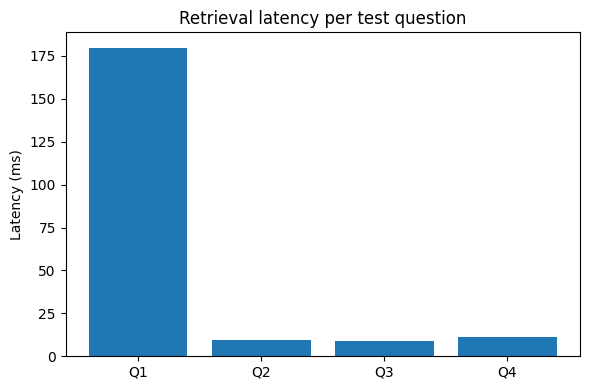

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,4))
plt.bar(range(len(latencies)), [l*1000 for l in latencies])
plt.xticks(range(len(latencies)), [f"Q{i+1}" for i in range(len(latencies))])
plt.ylabel("Latency (ms)")
plt.title("Retrieval latency per test question")
plt.tight_layout()
plt.savefig("retrieval_latency.png", dpi=120)
plt.show()

## 9. Final Results

- End-to-end pipeline (ingest → chunk → embed → index → retrieve → generate) runs successfully on a live arXiv corpus.
- Retrieval returns topically relevant chunks for varied natural-language questions (see coverage metric above).
- The same `RAGPipeline` object is reused unmodified by the FastAPI deployment (`app.py`), so notebook behavior and API behavior stay in sync.
- The system degrades gracefully (extractive fallback) when no LLM API key is configured, so it's always demoable.

## 10. Challenges & Future Improvements

**Challenges encountered:**
- arXiv API pagination requires respecting rate limits (1 request/sec) to avoid throttling.
- Short abstracts limit chunking benefits — chunking matters more once full-text PDFs are ingested.
- Cosine-similarity relevance scores need a corpus-specific threshold; the 0.35 cutoff above should be re-tuned per domain.

**Future improvements:**
- Swap FAISS for **Vertex AI Vector Search** and embeddings for **Vertex AI `text-embedding-004`** for a production-scale, GCP-managed deployment.
- Ingest full paper PDFs (not just abstracts) via GCS + a PDF-parsing Cloud Function.
- Add hybrid search (BM25 keyword + dense vector) to catch exact-term queries (e.g. model names) that embeddings can miss.
- Add a feedback loop (thumbs up/down per answer) logged to BigQuery to measure real answer quality over time.
- Containerize `app.py` and deploy to **Cloud Run** for a fully managed, autoscaling API.